# Machine Learning techniques for analysing Factors Influencing Customer Ratings of Amazon Bestselling Books


## 1. Introduction
#### This project investigates the relationship between selected product features and customer ratings of Amazon bestselling books using machine learning techniques. The analysis examines product attributes including price, review count, number of pages, bestseller rank, and genre to determine their relationship with customer ratings. The dataset contains information on Amazon bestselling books available up to the end of 2023. The study involves data preparation, exploratory data analysis, statistical testing, and supervised machine learning modelling. Four regression models are developed and compared using R², RMSE, and MAE to evaluate their effectiveness in predicting customer ratings. The findings aim to provide insights that can contribute to understanding product success and decision-making in an e-commerce environment.



## 2. Setup and Data Loading
### 2.1 Importing Libraries¶

In [546]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

## 2.2 Loading the Dataset

In [547]:
df=pd.read_csv("Amazon-books.csv")
df.head(10)

,Title,Rank,Reviews,Review Count,Price,Genre,Manufacturer,Brand,Author,Number of Pages
0,"Fourth Wing (The Empyrean, 1)",1,4.8,135916,18.69,Fantasy,Entangled: Red Tower Books,Macmillan,Rebecca Yarros,528.0
1,Atomic Habits: An Easy & Proven Way to Build G...,2,4.8,120356,12.50,Personal Transformation,Avery,Avery,James Clear,320.0
2,"Iron Flame (The Empyrean, 2)",3,4.7,79851,14.78,Epic,Entangled: Red Tower Books,Kiligry,Rebecca Yarros,640.0
3,"Dinner Tonight: 100 Simple, Healthy Recipes fo...",4,4.1,6,26.00,Natural Foods,William Morrow Cookbooks,NaN,Alex Snodgrass,256.0
4,Oath and Honor: A Memoir and a Warning,5,4.8,3536,21.49,Political,"Little, Brown and Company",NaN,Liz Cheney,384.0
5,The Heaven & Earth Grocery Store: A Novel,6,4.5,15178,16.99,Jewish,Riverhead Books,NaN,James McBride,400.0
6,Icebreaker: A Novel (The Maple Hills Series),7,4.4,61258,10.44,Contemporary,Atria,NaN,Hannah Grace,448.0
7,Interesting Facts For Curious Minds: 1572 Rand...,8,4.5,8072,12.48,Trivia & Fun Facts,Red Panda Press,SEAJEA,Jordan Moore,198.0
8,Winter Turning: A Graphic Novel (Wings of Fire...,9,5.0,1,10.39,Animals,Graphix,NaN,Tui T. Sutherland,224.0
9,"Ruthless Vows (Letters of Enchantment, 2)",10,5.0,1,14.98,Romance,Wednesday Books,NaN,Rebecca Ross,432.0


In [548]:
df["Author"].nunique()

2901

In [549]:
df["Author"].value_counts().head(40)

Author
Calendars Workman          40
Sarah J. Maas              36
Ltd. Publications          32
Colleen Hoover             27
Gege Akutami               21
Jeff Kinney                21
Publishing Workman         20
Dav Pilkey                 19
Kitchen America's          19
Rick Riordan               19
Sandra Boynton             17
International Trends       17
Brandon Sanderson          17
Zondervan Zondervan        17
Sourcebooks Sourcebooks    17
Publications Editors       16
Tui T. Sutherland          16
Freida McFadden            15
DK DK                      15
J. K. Rowling              15
Licenses Penguin           14
Kentaro Miura              13
Publishers Christian       13
Stephen King               13
Dragons Dungeons           13
Tatsuki Fujimoto           13
Nelson Thomas              13
Mo Willems                 12
Tyndale Tyndale            12
Jennifer Lynn Barnes       12
Seuss Dr                   12
Gifts Christian            12
Jennifer L. Armentrout     12
Xiu

In [550]:
author_counts = df['Author'].value_counts()

print(author_counts.describe())
print(author_counts.head(20))

count    2901.000000
mean        1.670458
std         2.206804
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max        40.000000
Name: count, dtype: float64
Author
Calendars Workman          40
Sarah J. Maas              36
Ltd. Publications          32
Colleen Hoover             27
Gege Akutami               21
Jeff Kinney                21
Publishing Workman         20
Dav Pilkey                 19
Kitchen America's          19
Rick Riordan               19
Sandra Boynton             17
International Trends       17
Brandon Sanderson          17
Zondervan Zondervan        17
Sourcebooks Sourcebooks    17
Publications Editors       16
Tui T. Sutherland          16
Freida McFadden            15
DK DK                      15
J. K. Rowling              15
Name: count, dtype: int64


In [551]:
print((author_counts == 1).sum())
print((author_counts <= 2).sum())
print((author_counts <= 5).sum())
print((author_counts >= 10).sum())

2190
2566
2800
39


## 3. Initial Data Overview

### 3.1 Dataset Dimensions

In [552]:
df.shape

(4846, 10)

### 3.2 Dataset Structure

In [553]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4846 entries, 0 to 4845
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Title            4846 non-null   object 
 1   Rank             4846 non-null   int64  
 2   Reviews          4846 non-null   float64
 3   Review Count     4846 non-null   int64  
 4   Price            4846 non-null   float64
 5   Genre            4846 non-null   object 
 6   Manufacturer     4846 non-null   object 
 7   Brand            3144 non-null   object 
 8   Author           4846 non-null   object 
 9   Number of Pages  4775 non-null   float64
dtypes: float64(3), int64(2), object(5)
memory usage: 378.7+ KB


### 3.3 Summary Statistics

In [554]:
df.describe()

,Rank,Reviews,Review Count,Price,Number of Pages
count,4846.000000,4846.000000,4846.000000,4846.000000,4775.000000
mean,2533.388774,4.662299,12735.633306,13.098601,347.739686
std,1500.594167,0.225194,28780.356812,10.248512,415.874433
min,1.000000,1.000000,1.000000,0.150000,1.000000
25%,1242.750000,4.600000,943.500000,7.412500,128.000000
50%,2501.500000,4.700000,4010.000000,11.100000,272.000000
75%,3768.750000,4.800000,12033.000000,15.667500,408.000000
max,15176.000000,5.000000,621499.000000,199.990000,5280.000000


### 3.4 Missing Values

In [555]:
print(df.isnull().sum())

Title                 0
Rank                  0
Reviews               0
Review Count          0
Price                 0
Genre                 0
Manufacturer          0
Brand              1702
Author                0
Number of Pages      71
dtype: int64


# 4. Data Cleaning 

The dataset contained some observations that were not books. These observations were removed because the research focuses specifically on Amazon bestselling books.

In [556]:
df["Number of Pages"].value_counts()

Number of Pages
320.0     162
224.0     132
384.0     127
24.0      126
304.0     125
         ... 
365.0       1
5008.0      1
357.0       1
2752.0      1
222.0       1
Name: count, Length: 630, dtype: int64

In [557]:
#which book has max number of pages 
df.loc[df["Number of Pages"] == df["Number of Pages"].max()]

,Title,Rank,Reviews,Review Count,Price,Genre,Manufacturer,Brand,Author,Number of Pages
2912,A Game of Thrones / A Clash of Kings / A Storm...,3016,4.7,52100,48.95,TV,Bantam,Bantam,George R. R. Martin,5280.0


In [558]:
#which book has min number of pages 
df.loc[df["Number of Pages"] == df["Number of Pages"].min()]

,Title,Rank,Reviews,Review Count,Price,Genre,Manufacturer,Brand,Author,Number of Pages
741,Metal Stencil Bookmark for Bullet Journals,769,4.5,7849,4.53,Bookmarks,"Peter Pauper Press, Inc.",PETER PAUPER PRESS,Inc. Peter Pauper Press,1.0
1106,Rand McNally Folded Map: United States Map,1140,4.8,2501,6.32,Atlases & Gazetteers,Rand McNally,Rand McNally,McNally Rand,1.0
2348,"Not Meow, I'm Reading Beaded Bookmark, Cardstock",2430,4.8,5000,2.95,Book Covers & Book Accessories,Peter Pauper Press,PETER PAUPER PRESS,Press Peter,1.0
2677,A Wise Woman Once Said Beaded Cardstock Bookmark,2779,4.8,1189,2.95,Bookmarks,Peter Pauper Press,PETER PAUPER PRESS,Press Peter,1.0
3762,"Coffee & Books Beaded Bookmark,1Pc",3912,4.8,5037,2.95,Bookmarks,"Peter Pauper Press, Inc.",PETER PAUPER PRESS,Press Inc,1.0
3981,The Ultimate Reading Challenge: Complete a Goa...,4157,4.6,709,22.99,Creativity,Weldon Owen,NaN,Owen Weldon,1.0
4389,She is Clothed with Strength and Dignity Beade...,4616,4.8,3393,2.95,Book Covers & Book Accessories,Peter Pauper Press,PETER PAUPER PRESS,Press Peter,1.0


In [559]:
df[df["Number of Pages"] <= 10][
    ["Title", "Rank", "Price", "Genre", "Manufacturer", "Author", "Number of Pages"]
]

,Title,Rank,Price,Genre,Manufacturer,Author,Number of Pages
414,Wild Animals: A Touch and Feel Book - Children...,432,5.09,Animals,Little Hippo Books,Books Little,10.0
468,Ocean Friends - Touch and Feel Board Book - Se...,483,8.99,Children's Books,Little Hippo Books,Books Little,10.0
741,Metal Stencil Bookmark for Bullet Journals,769,4.53,Bookmarks,"Peter Pauper Press, Inc.",Inc. Peter Pauper Press,1.0
1036,Under the Sea - Silicone Touch and Feel Board ...,1072,9.89,Children's Books,Little Hippo Books,Books Little,10.0
1106,Rand McNally Folded Map: United States Map,1140,6.32,Atlases & Gazetteers,Rand McNally,McNally Rand,1.0
1140,Backyard Bugs - Touch and Feel Board Book - Se...,1176,8.72,Children's Books,Little Hippo Books,Books Little,10.0
1256,"Peek-a Who? (Lift the Flap Books, Interactive ...",1289,3.52,Games,Chronicle Books,Nina Laden,10.0
1330,The Very Hungry Caterpillar's Peekaboo Christm...,1370,4.99,Animals,World of Eric Carle,Eric Carle,10.0
1476,National Park Quarters: 50 States + District o...,1522,4.50,Coin Folders,Krause Publications,Warman's Warman's,3.0
1480,Disney Pixar Cars 3 - Lightning McQueen and Fr...,1526,10.95,Entertainment & Games,"Phoenix International Publications, Inc.",Publications Editors,10.0


In [560]:
count_low_pages = (df["Number of Pages"] <= 10).sum()
percentage_low_pages = (count_low_pages / len(df)) * 100

print("Count:", count_low_pages)
print("Percentage:", percentage_low_pages)

Count: 42
Percentage: 0.8666941807676434


In [561]:
df[df["Number of Pages"] <= 10]["Title"].tolist()

["Wild Animals: A Touch and Feel Book - Children's Board Book - Educational",
 'Ocean Friends - Touch and Feel Board Book - Sensory Board Book',
 'Metal Stencil Bookmark for Bullet Journals',
 'Under the Sea - Silicone Touch and Feel Board Book - Sensory Board Book',
 'Rand McNally Folded Map: United States Map',
 'Backyard Bugs - Touch and Feel Board Book - Sensory Board Book',
 'Peek-a Who? (Lift the Flap Books, Interactive Books for Kids, Interactive Read Aloud Books)',
 "The Very Hungry Caterpillar's Peekaboo Christmas (The World of Eric Carle)",
 "National Park Quarters: 50 States + District of Columbia & Territories: Collector's Quarters Folder 2010 -2021 (Warman's Collector Coin Folders)",
 'Disney Pixar Cars 3 - Lightning McQueen and Friends Little Sound Book - Play-a-Sound - PI Kids',
 'Original Wizard Card Game',
 'Ekgs / Ecgs (Quick Study Academic)',
 "Daniel Tiger's Potty Time! Children's Toilet Training Sound Book for Daniel Tiger Fans ( )",
 'Excel Formulas (Quick Study C

In [562]:
#out of scope books 
out_of_scope_titles = [
    "Metal Stencil Bookmark for Bullet Journals",
    "Rand McNally Folded Map: United States Map",
    "National Park Quarters: 50 States + District of Columbia & Territories: Collector's Quarters Folder 2010 -2021 (Warman's Collector Coin Folders)",
    "Original Wizard Card Game",
    "State Quarter 1999-2009: Collector's State Quarter Folder",
    "Not Meow, I'm Reading Beaded Bookmark, Cardstock",
    "A Wise Woman Once Said Beaded Cardstock Bookmark",
    "50 State Quarters Map (includes space for the Philadelphia and Denver mints!)",
    "Coffee & Books Beaded Bookmark,1Pc",
    "Blackjack Basic Strategy Chart: 4/6/8 Decks, Dealer Hits Soft 17",
    "Lincoln Cents 1909-1958 Collector's Folder (Warman's Collector Coin Folders)",
    "Origami Paper 500 sheets Chiyogami Patterns 6\" 15cm",
    "She is Clothed with Strength and Dignity Beaded Bookmark"]

In [563]:
out_of_scope = df[df["Title"].isin(out_of_scope_titles)]

out_of_scope[["Title", "Number of Pages"]]

,Title,Number of Pages
741,Metal Stencil Bookmark for Bullet Journals,1.0
1106,Rand McNally Folded Map: United States Map,1.0
1476,National Park Quarters: 50 States + District o...,3.0
1864,Original Wizard Card Game,2.0
2264,State Quarter 1999-2009: Collector's State Qua...,3.0
2348,"Not Meow, I'm Reading Beaded Bookmark, Cardstock",1.0
2677,A Wise Woman Once Said Beaded Cardstock Bookmark,1.0
2800,50 State Quarters Map (includes space for the ...,3.0
3762,"Coffee & Books Beaded Bookmark,1Pc",1.0
3780,"Blackjack Basic Strategy Chart: 4/6/8 Decks, D...",2.0


In [564]:
print("Number of records to remove:", len(out_of_scope))

Number of records to remove: 13


In [565]:

# Remove rows where the Title column contains values that are in the out_of_scope_titles list
# The ~ operator negates the boolean mask, keeping only titles NOT in the exclusion list
df = df[~df["Title"].isin(out_of_scope_titles)]

In [566]:
print("Remaining records:", len(df))

Remaining records: 4833


In [567]:
#confirm none book items were succesfully removed
df[df["Number of Pages"] <= 10][
    ["Title", "Rank", "Price", "Genre", "Manufacturer", "Author", "Number of Pages"]]

,Title,Rank,Price,Genre,Manufacturer,Author,Number of Pages
414,Wild Animals: A Touch and Feel Book - Children...,432,5.09,Animals,Little Hippo Books,Books Little,10.0
468,Ocean Friends - Touch and Feel Board Book - Se...,483,8.99,Children's Books,Little Hippo Books,Books Little,10.0
1036,Under the Sea - Silicone Touch and Feel Board ...,1072,9.89,Children's Books,Little Hippo Books,Books Little,10.0
1140,Backyard Bugs - Touch and Feel Board Book - Se...,1176,8.72,Children's Books,Little Hippo Books,Books Little,10.0
1256,"Peek-a Who? (Lift the Flap Books, Interactive ...",1289,3.52,Games,Chronicle Books,Nina Laden,10.0
1330,The Very Hungry Caterpillar's Peekaboo Christm...,1370,4.99,Animals,World of Eric Carle,Eric Carle,10.0
1480,Disney Pixar Cars 3 - Lightning McQueen and Fr...,1526,10.95,Entertainment & Games,"Phoenix International Publications, Inc.",Publications Editors,10.0
2012,Ekgs / Ecgs (Quick Study Academic),2068,6.95,Medical,QuickStudy,Inc. BarCharts,6.0
2071,Daniel Tiger's Potty Time! Children's Toilet T...,2136,8.00,Lions,Cottage Door Press,Wing Scarlett,10.0
2099,Excel Formulas (Quick Study Computer),2167,5.62,Spreadsheets,QuickStudy,Inc. BarCharts,6.0


### 4.2 Handling Missing Values

The Brand variable contained a substantial number of missing observations and was removed from the analysis. Missing values in Number of Pages were handled using median imputation to retain observations while limiting the influence of extreme values.

In [568]:
df["Brand"].value_counts()

Brand
Scholastic                          98
VIZ Media LLC                       56
Rockridge Press                     53
Thomas Nelson                       46
Penguin Books                       46
                                    ..
Cider Mill Press                     1
Try Not To Laugh Challenge Group     1
Martino Fine Books                   1
Merriam-Webster, Inc                 1
Send The Light Distribution          1
Name: count, Length: 756, dtype: int64

In [569]:
summary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isnull().sum(),
    "Unique Values": df.nunique()
})

summary

,Column,Data Type,Missing Values,Unique Values
Title,Title,object,0,4745
Rank,Rank,int64,0,4019
Reviews,Reviews,float64,0,24
Review Count,Review Count,int64,0,3753
Price,Price,float64,0,1739
Genre,Genre,object,0,902
Manufacturer,Manufacturer,object,0,970
Brand,Brand,object,1702,756
Author,Author,object,0,2897
Number of Pages,Number of Pages,float64,71,628


In [570]:
# Calculate the percentage of missing values in the 'Brand' column
df["Brand"].isna().mean() * 100

np.float64(35.216221808400576)

In [571]:
df[["Rank", "Reviews", "Review Count", "Price", "Number of Pages"]].describe()

,Rank,Reviews,Review Count,Price,Number of Pages
count,4833.000000,4833.000000,4833.000000,4833.000000,4762.000000
mean,2532.555556,4.662094,12756.135320,13.119388,348.682486
std,1501.121102,0.225412,28815.860846,10.253462,416.049544
min,1.000000,1.000000,1.000000,0.150000,1.000000
25%,1240.000000,4.600000,940.000000,7.480000,128.000000
50%,2501.000000,4.700000,4009.000000,11.130000,273.500000
75%,3765.000000,4.800000,12083.000000,15.700000,408.000000
max,15176.000000,5.000000,621499.000000,199.990000,5280.000000


In [572]:
#Drop Brand 
df = df.drop(columns=["Brand"])

In [573]:
df.shape

(4833, 9)

In [574]:
#handle missing:number of pages
df["Number of Pages"].describe()

count    4762.000000
mean      348.682486
std       416.049544
min         1.000000
25%       128.000000
50%       273.500000
75%       408.000000
max      5280.000000
Name: Number of Pages, dtype: float64

In [575]:
#median imputation for missing values:Number of pages
median_pages = df["Number of Pages"].median()

df["Number of Pages"] = df["Number of Pages"].fillna(median_pages)

In [576]:
#missing values removed 
df["Number of Pages"].isnull().sum()

np.int64(0)

In [577]:
median_pages

np.float64(273.5)

In [578]:
df.isnull().sum()

Title              0
Rank               0
Reviews            0
Review Count       0
Price              0
Genre              0
Manufacturer       0
Author             0
Number of Pages    0
dtype: int64

### 4.3 Checking Duplicate Titles

In [579]:
#check duplicated titles
df["Title"].duplicated().sum()

np.int64(88)

In [580]:
df[df["Title"].duplicated(keep=False)].sort_values("Title")

,Title,Rank,Reviews,Review Count,Price,Genre,Manufacturer,Author,Number of Pages
652,$100M Leads: How to Get Strangers To Want To B...,675,4.9,2762,24.26,Advertising,Acquisition.com Publishing,Alex Hormozi,279.0
2959,$100M Leads: How to Get Strangers To Want To B...,3062,4.9,2762,26.99,Advertising,Acquisition.com Publishing,Alex Hormozi,279.0
2530,$100M Offers: How To Make Offers So Good Peopl...,2626,4.9,19843,22.46,Advertising,Acquisition.com Publishing,Alex Hormozi,162.0
1237,$100M Offers: How To Make Offers So Good Peopl...,1273,4.9,19844,26.95,Advertising,Acquisition.com Publishing,Alex Hormozi,162.0
2473,A Court of Frost and Starlight (A Court of Tho...,2554,4.3,84605,8.99,Folklore,Bloomsbury Publishing,Sarah J. Maas,240.0
...,...,...,...,...,...,...,...,...,...
4235,Vanderbilt: The Rise and Fall of an American D...,4434,4.3,16860,10.87,Criticism,Harper,Anderson Cooper,336.0
2328,Verity,2406,4.6,319252,11.05,Genre Fiction,Grand Central Publishing,Colleen Hoover,368.0
59,Verity,61,4.6,319253,6.48,Psychological Thrillers,Grand Central Publishing,Winning Moves Games,336.0
2665,Where the Crawdads Sing: Reese's Book Club (A ...,2767,4.7,621499,5.19,Coming of Age,G.P. Putnam's Sons,Delia Owens,384.0


In [581]:
duplicates = df[df["Title"].duplicated(keep=False)].sort_values("Title")

duplicates[[
    "Title",
    "Rank",
    "Reviews",
    "Review Count",
    "Price",
    "Genre",
    "Manufacturer",
    "Author",
    "Number of Pages"
]]

,Title,Rank,Reviews,Review Count,Price,Genre,Manufacturer,Author,Number of Pages
652,$100M Leads: How to Get Strangers To Want To B...,675,4.9,2762,24.26,Advertising,Acquisition.com Publishing,Alex Hormozi,279.0
2959,$100M Leads: How to Get Strangers To Want To B...,3062,4.9,2762,26.99,Advertising,Acquisition.com Publishing,Alex Hormozi,279.0
2530,$100M Offers: How To Make Offers So Good Peopl...,2626,4.9,19843,22.46,Advertising,Acquisition.com Publishing,Alex Hormozi,162.0
1237,$100M Offers: How To Make Offers So Good Peopl...,1273,4.9,19844,26.95,Advertising,Acquisition.com Publishing,Alex Hormozi,162.0
2473,A Court of Frost and Starlight (A Court of Tho...,2554,4.3,84605,8.99,Folklore,Bloomsbury Publishing,Sarah J. Maas,240.0
...,...,...,...,...,...,...,...,...,...
4235,Vanderbilt: The Rise and Fall of an American D...,4434,4.3,16860,10.87,Criticism,Harper,Anderson Cooper,336.0
2328,Verity,2406,4.6,319252,11.05,Genre Fiction,Grand Central Publishing,Colleen Hoover,368.0
59,Verity,61,4.6,319253,6.48,Psychological Thrillers,Grand Central Publishing,Winning Moves Games,336.0
2665,Where the Crawdads Sing: Reese's Book Club (A ...,2767,4.7,621499,5.19,Coming of Age,G.P. Putnam's Sons,Delia Owens,384.0


Observation: A total of 88 duplicate titles were identified. However, the records were not removed because books with the same title had different prices and numbers of pages. This suggests that some records may represent different editions or formats of the same book. Therefore, the observations were retained to avoid removing potentially valid data.

In [582]:
df.shape

(4833, 9)

In [583]:
df.isnull().sum()

Title              0
Rank               0
Reviews            0
Review Count       0
Price              0
Genre              0
Manufacturer       0
Author             0
Number of Pages    0
dtype: int64

## 5. Exploratory Data Analysis

### 5.1 Customer Rating Analysis

In [584]:
df["Reviews"].describe()

count    4833.000000
mean        4.662094
std         0.225412
min         1.000000
25%         4.600000
50%         4.700000
75%         4.800000
max         5.000000
Name: Reviews, dtype: float64

In [585]:
df["Reviews"].value_counts()

Reviews
4.8    1295
4.7    1062
4.6     683
4.9     609
4.5     398
4.4     304
4.3     192
5.0      84
4.2      77
4.1      57
4.0      26
3.9      12
3.8       9
3.7       7
3.5       6
3.6       4
3.4       1
3.1       1
3.3       1
3.0       1
2.1       1
2.5       1
2.6       1
1.0       1
Name: count, dtype: int64

In [586]:
#highest reviews
df.loc[df["Reviews"] == df["Reviews"].max()]

,Title,Rank,Reviews,Review Count,Price,Genre,Manufacturer,Author,Number of Pages
8,Winter Turning: A Graphic Novel (Wings of Fire...,9,5.0,1,10.39,Animals,Graphix,Tui T. Sutherland,224.0
9,"Ruthless Vows (Letters of Enchantment, 2)",10,5.0,1,14.98,Romance,Wednesday Books,Rebecca Ross,432.0
270,Claudia and the Bad Joke: A Graphic Novel (The...,280,5.0,1,10.38,Babysitting,Graphix,Ann M. Martin,192.0
395,Bob's Burgers 2024 Wall Calendar,411,5.0,62,12.79,Performing Arts,Rizzoli Universe,Inc. Twentieth,24.0
484,More! More! More!,500,5.0,333,14.99,Family Life,Trufflery,Barbara Rieco,38.0
...,...,...,...,...,...,...,...,...,...
4613,Sonic the Hedgehog 2024 Wall Calendar,4883,5.0,14,12.12,Video Games,Harry N Abrams Inc.,Sega Sega,24.0
4664,5 Minutes to Happiness: Gratitude Journal for ...,4956,5.0,1,8.98,Happiness,Happiness Creators,Creators Happiness,116.0
4760,Of Ashes,5217,5.0,4,13.00,Mystery & Suspense,Independently published,Anna Miriam Brown,526.0
4792,Mi hija es astronauta (Spanish Edition),5421,5.0,27,14.39,Motivational,Independently published,Claudia Valdés,151.0


In [587]:
#lowest reviews
df.loc[df["Reviews"] == df["Reviews"].min()]

,Title,Rank,Reviews,Review Count,Price,Genre,Manufacturer,Author,Number of Pages
4798,Bobby Goods Kids Coloring: 80+ Cute Bobby Good...,5462,1.0,1,6.94,Coloring Books,Independently published,Immanuel Publish,80.0


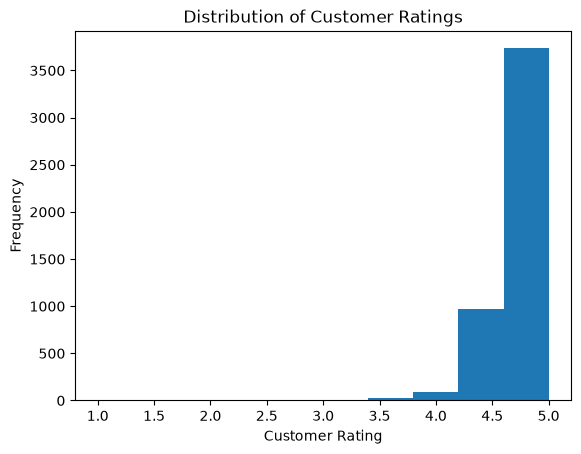

In [588]:
plt.hist(df["Reviews"])

plt.title("Distribution of Customer Ratings")
plt.xlabel("Customer Rating")
plt.ylabel("Frequency")

plt.show()

### 5.2 Price Analysis

In [589]:
df["Price"].describe()

count    4833.000000
mean       13.119388
std        10.253462
min         0.150000
25%         7.480000
50%        11.130000
75%        15.700000
max       199.990000
Name: Price, dtype: float64

In [590]:
df["Price"].value_counts()

Price
9.99     69
7.99     67
6.99     52
5.99     47
12.99    46
         ..
11.34     1
23.66     1
6.81      1
27.23     1
17.19     1
Name: count, Length: 1739, dtype: int64

In [591]:
#highest priced book
df.loc[df["Price"] == df["Price"].max()]

,Title,Rank,Reviews,Review Count,Price,Genre,Manufacturer,Author,Number of Pages
2650,"MCAT Complete 7-Book Subject Review 2024-2025,...",2749,4.8,88,199.99,Test Preparation & Review,Kaplan Test Prep,Prep Kaplan,3520.0


In [592]:
#lowest priced book
df.loc[df["Price"] == df["Price"].min()]

,Title,Rank,Reviews,Review Count,Price,Genre,Manufacturer,Author,Number of Pages
4120,cahier séyès: cahier grands Carreaux 196 pages...,4301,5.0,1,0.15,Schools & Teaching,Independently published,Juliette Juliette,196.0


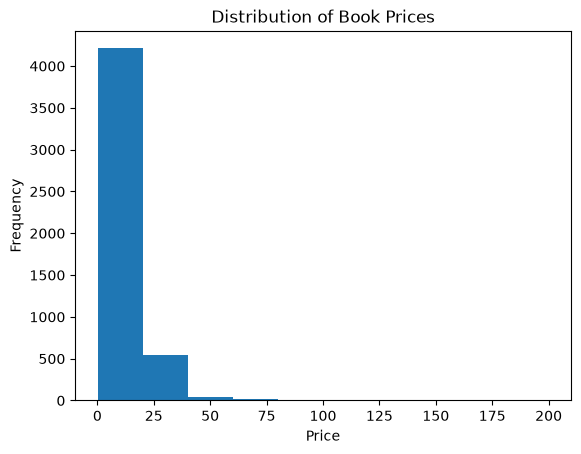

In [593]:
plt.hist(df["Price"])

plt.title("Distribution of Book Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

### 5.3 Review Count Analysis

In [594]:
df["Review Count"].value_counts()

Review Count
1        12
17       12
21       11
12       11
18       10
         ..
1490      1
21432     1
2910      1
35539     1
5967      1
Name: count, Length: 3753, dtype: int64

In [595]:
df["Review Count"].describe()

count      4833.000000
mean      12756.135320
std       28815.860846
min           1.000000
25%         940.000000
50%        4009.000000
75%       12083.000000
max      621499.000000
Name: Review Count, dtype: float64

In [596]:
#highest review count 
df.loc[df["Review Count"] == df["Review Count"].max()]

,Title,Rank,Reviews,Review Count,Price,Genre,Manufacturer,Author,Number of Pages
436,Where the Crawdads Sing: Reese's Book Club (A ...,455,4.7,621499,4.99,Coming of Age,G.P. Putnam's Sons,Delia Owens,400.0
2665,Where the Crawdads Sing: Reese's Book Club (A ...,2767,4.7,621499,5.19,Coming of Age,G.P. Putnam's Sons,Delia Owens,384.0


In [597]:
#lowest review count 
df.loc[df["Review Count"] == df["Review Count"].min()]

,Title,Rank,Reviews,Review Count,Price,Genre,Manufacturer,Author,Number of Pages
8,Winter Turning: A Graphic Novel (Wings of Fire...,9,5.0,1,10.39,Animals,Graphix,Tui T. Sutherland,224.0
9,"Ruthless Vows (Letters of Enchantment, 2)",10,5.0,1,14.98,Romance,Wednesday Books,Rebecca Ross,432.0
270,Claudia and the Bad Joke: A Graphic Novel (The...,280,5.0,1,10.38,Babysitting,Graphix,Ann M. Martin,192.0
651,Journey of Us: 101 Challenges for Couples,674,5.0,1,14.99,Dating,Independently published,Amour Editions,205.0
3356,Rebel Moon Part One - A Child Of Fire: The Off...,3478,3.0,1,11.23,TV,Titan Books,V. Castro,272.0
3814,The Illustrated Word: An Artists Collection of...,3963,5.0,1,17.96,Bibles,Radiant Publishing,Adam Creagon,128.0
4120,cahier séyès: cahier grands Carreaux 196 pages...,4301,5.0,1,0.15,Schools & Teaching,Independently published,Juliette Juliette,196.0
4323,Super Game Book!: A Branches Special Edition (...,4540,5.0,1,7.92,Chapter Books,Scholastic Inc.,Thomas Flintham,144.0
4353,Butterflies And Flowers: Explore the Magic of ...,4568,5.0,1,7.99,Animals,Independently published,Matsuko Zenito,108.0
4502,Dark Enemies: Special Edition Blue (McGowan Ma...,4752,5.0,1,19.32,Action & Adventure,Independently published,Effie Campbell,252.0


### 5.4 Bestseller Rank Analysis

In [598]:
df["Rank"].value_counts()

Rank
3054     4
4397     3
4276     3
3881     3
1486     3
        ..
1722     1
1723     1
1724     1
1725     1
15176    1
Name: count, Length: 4019, dtype: int64

In [599]:
df["Rank"].describe()

count     4833.000000
mean      2532.555556
std       1501.121102
min          1.000000
25%       1240.000000
50%       2501.000000
75%       3765.000000
max      15176.000000
Name: Rank, dtype: float64

In [600]:
#highest Rank 
df.loc[df["Rank"] == df["Rank"].max()]

,Title,Rank,Reviews,Review Count,Price,Genre,Manufacturer,Author,Number of Pages
4845,In the Fullness of Time: 32 Women on Life Afte...,15176,4.1,29,17.19,Love & Loss,Atria,Emily W. Upham,276.0


In [601]:
#lowest Rank 
df.loc[df["Rank"] == df["Rank"].min()]

,Title,Rank,Reviews,Review Count,Price,Genre,Manufacturer,Author,Number of Pages
0,"Fourth Wing (The Empyrean, 1)",1,4.8,135916,18.69,Fantasy,Entangled: Red Tower Books,Rebecca Yarros,528.0


### 5.5 Number of Pages Analysis

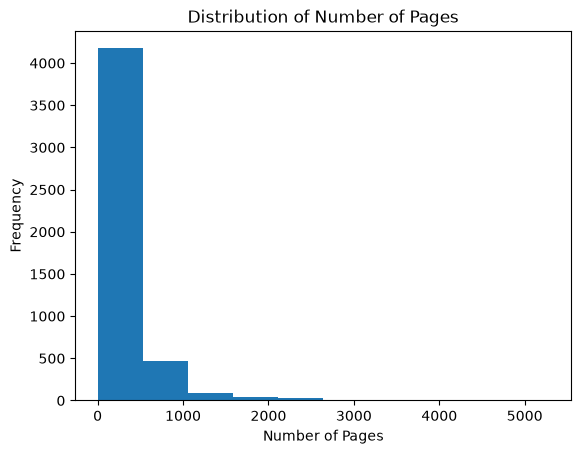

In [602]:
plt.hist(df["Number of Pages"])

plt.title("Distribution of Number of Pages")
plt.xlabel("Number of Pages")
plt.ylabel("Frequency")

plt.show()

### 5.6 Genre Analysis

In [603]:
df["Genre"].nunique()

902

In [604]:
genre_counts = df["Genre"].value_counts()

genre_counts

Genre
Fantasy               176
Classics              105
Genre Fiction         101
Motivational           99
Animals                95
                     ... 
Relationships           1
Mariology               1
Fruit                   1
Programming             1
Trading Card Games      1
Name: count, Length: 902, dtype: int64

In [605]:
genre_counts.head(10)

Genre
Fantasy             176
Classics            105
Genre Fiction       101
Motivational         99
Animals              95
Bibles               95
Happiness            78
Children's Books     72
Contemporary         72
Friendship           66
Name: count, dtype: int64

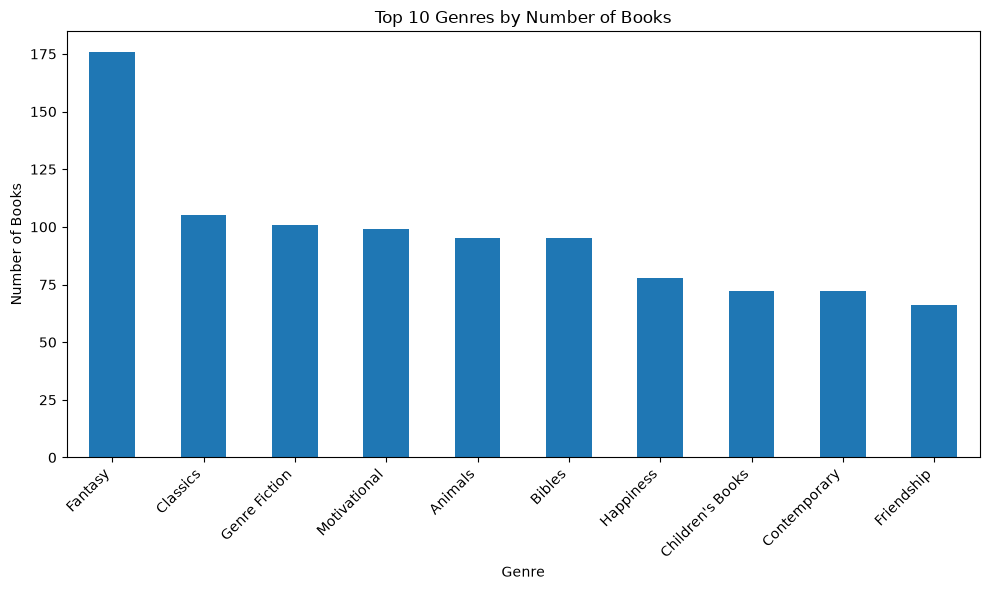

In [606]:
plt.figure(figsize=(10, 6))

genre_counts.head(10).plot(kind="bar")

plt.xlabel("Genre")
plt.ylabel("Number of Books")
plt.title("Top 10 Genres by Number of Books")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [607]:
# Iterate through different threshold values to analyze genre distribution
for threshold in [2, 5, 10, 20, 30]:
    # Count how many genres have at least 'threshold' number of books
    categories = (genre_counts >= threshold).sum()
    # Display the threshold and resulting number of genres that meet the criteria
    print(threshold, "books per genre →", categories, "genres retained")

2 books per genre → 502 genres retained
5 books per genre → 216 genres retained
10 books per genre → 103 genres retained
20 books per genre → 47 genres retained
30 books per genre → 32 genres retained


#### A minimum threshold of 5 books per genre was selected.

In [608]:
#groups rare genres 
genre_counts = df["Genre"].value_counts()

df["Genre_Grouped"] = df["Genre"].where(
    df["Genre"].map(genre_counts) >= 5,
    "Other"
)

In [609]:
df["Genre_Grouped"].value_counts().head(10)

Genre_Grouped
Other               1140
Fantasy              176
Classics             105
Genre Fiction        101
Motivational          99
Animals               95
Bibles                95
Happiness             78
Children's Books      72
Contemporary          72
Name: count, dtype: int64

In [610]:
top_genres = df["Genre_Grouped"].value_counts().head(10).index

genre_ratings = (
    df[df["Genre_Grouped"].isin(top_genres)]
    .groupby("Genre_Grouped")["Reviews"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("median", ascending=False)
)

genre_ratings

,count,mean,median,std
Genre_Grouped,,,,
Animals,95,4.787368,4.8,0.115078
Bibles,95,4.820000,4.8,0.099574
Fantasy,176,4.755114,4.8,0.187851
Children's Books,72,4.677778,4.7,0.145566
Classics,105,4.674286,4.7,0.169291
Happiness,78,4.651282,4.7,0.158519
Motivational,99,4.718182,4.7,0.146638
Other,1140,4.652368,4.7,0.194804
Contemporary,72,4.473611,4.5,0.207597


In [611]:
genre_data = df[
    df["Genre_Grouped"].isin(top_genres)]

## 5.7 Relationship Between Variables

### Correlation Analysis

In [612]:
correlation_matrix = df[
    [
        "Reviews",
        "Price",
        "Review Count",
        "Rank",
        "Number of Pages"
    ]
].corr()

correlation_matrix

,Reviews,Price,Review Count,Rank,Number of Pages
Reviews,1.000000,0.095366,-0.120172,-0.008819,0.056096
Price,0.095366,1.000000,-0.105150,0.022296,0.577602
Review Count,-0.120172,-0.105150,1.000000,-0.172520,0.060971
Rank,-0.008819,0.022296,-0.172520,1.000000,0.016697
Number of Pages,0.056096,0.577602,0.060971,0.016697,1.000000


#### price and number of pages had the strongest relationship among the numerical variables

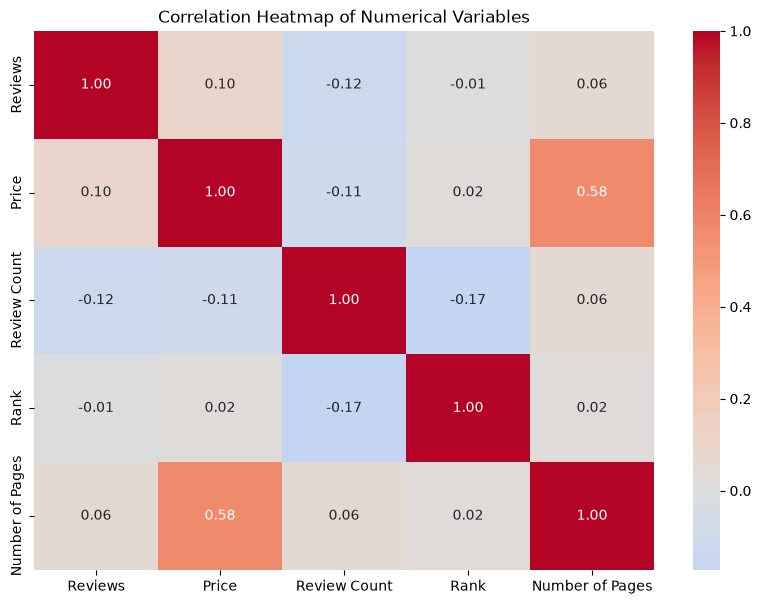

In [613]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical variables
correlation = df[
    ["Reviews", "Price", "Review Count", "Rank", "Number of Pages"]
].corr()

# Create heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

## 6. Statistical Testing

### 6.1 Pearson correlation

#### This tests whether there is a linear relationship between numerical variables.

In [614]:
from scipy.stats import pearsonr

variables = ["Price", "Review Count", "Rank", "Number of Pages"]

for variable in variables:
    correlation, p_value = pearsonr(df[variable], df["Reviews"])

    print(f"{variable} vs Reviews")
    print(f"Correlation: {correlation:.4f}")
    print(f"P-value: {p_value:.4f}")
    print()

Price vs Reviews
Correlation: 0.0954
P-value: 0.0000

Review Count vs Reviews
Correlation: -0.1202
P-value: 0.0000

Rank vs Reviews
Correlation: -0.0088
P-value: 0.5399

Number of Pages vs Reviews
Correlation: 0.0561
P-value: 0.0001



## 6.2 ANOVA

#### A one-way ANOVA was conducted to determine whether mean customer ratings differed significantly across the genre groups.

In [675]:
from scipy.stats import f_oneway

# Get the rating values for each genre
genre_groups = [
    group["Reviews"].values
    for name, group in df.groupby("Genre_Grouped")
]

# Perform ANOVA
f_statistic, p_value = f_oneway(*genre_groups)

print("F-statistic:", f_statistic)
print("P-value:", p_value)

F-statistic: 7.194360556574113
P-value: 9.707376461275523e-167


## 6.3 Tukey HSD

In [616]:
%pip install statsmodels


Python(69670) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [617]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey = pairwise_tukeyhsd(
    endog=genre_data["Reviews"],
    groups=genre_data["Genre_Grouped"],
    alpha=0.05
)

print(tukey)

          Multiple Comparison of Means - Tukey HSD, FWER=0.05           
     group1           group2      meandiff p-adj   lower   upper  reject
------------------------------------------------------------------------
         Animals           Bibles   0.0326 0.9725 -0.0535  0.1188  False
         Animals Children's Books  -0.1096 0.0072 -0.2023 -0.0168   True
         Animals         Classics  -0.1131 0.0009 -0.1971  -0.029   True
         Animals     Contemporary  -0.3138    0.0 -0.4065  -0.221   True
         Animals          Fantasy  -0.0323 0.9412 -0.1078  0.0433  False
         Animals    Genre Fiction  -0.2804    0.0 -0.3653 -0.1956   True
         Animals        Happiness  -0.1361 0.0001 -0.2268 -0.0454   True
         Animals     Motivational  -0.0692 0.2324 -0.1544  0.0161  False
         Animals            Other   -0.135    0.0 -0.1984 -0.0716   True
          Bibles Children's Books  -0.1422 0.0001  -0.235 -0.0495   True
          Bibles         Classics  -0.1457    0.0 -

In [618]:
# Convert Tukey results to a DataFrame
tukey_df = pd.DataFrame(
    data=tukey._results_table.data[1:],
    columns=tukey._results_table.data[0]
)

# Significant differences
significant = tukey_df[tukey_df["reject"] == True]

# Non-significant differences
not_significant = tukey_df[tukey_df["reject"] == False]

print("Significant comparisons:")
display(significant)

print("Non-significant comparisons:")
display(not_significant)

Significant comparisons:


,group1,group2,meandiff,p-adj,lower,upper,reject
1,Animals,Children's Books,-0.1096,0.0072,-0.2023,-0.0168,True
2,Animals,Classics,-0.1131,0.0009,-0.1971,-0.0290,True
3,Animals,Contemporary,-0.3138,0.0000,-0.4065,-0.2210,True
5,Animals,Genre Fiction,-0.2804,0.0000,-0.3653,-0.1956,True
6,Animals,Happiness,-0.1361,0.0001,-0.2268,-0.0454,True
8,Animals,Other,-0.1350,0.0000,-0.1984,-0.0716,True
9,Bibles,Children's Books,-0.1422,0.0001,-0.2350,-0.0495,True
10,Bibles,Classics,-0.1457,0.0000,-0.2298,-0.0617,True
11,Bibles,Contemporary,-0.3464,0.0000,-0.4391,-0.2536,True
13,Bibles,Genre Fiction,-0.3131,0.0000,-0.3979,-0.2282,True


Non-significant comparisons:


,group1,group2,meandiff,p-adj,lower,upper,reject
0,Animals,Bibles,0.0326,0.9725,-0.0535,0.1188,False
4,Animals,Fantasy,-0.0323,0.9412,-0.1078,0.0433,False
7,Animals,Motivational,-0.0692,0.2324,-0.1544,0.0161,False
12,Bibles,Fantasy,-0.0649,0.1664,-0.1405,0.0107,False
17,Children's Books,Classics,-0.0035,1.0000,-0.0943,0.0873,False
19,Children's Books,Fantasy,0.0773,0.0929,-0.0057,0.1604,False
21,Children's Books,Happiness,-0.0265,0.9974,-0.1235,0.0705,False
22,Children's Books,Motivational,0.0404,0.9299,-0.0515,0.1323,False
23,Children's Books,Other,-0.0254,0.9832,-0.0975,0.0467,False
27,Classics,Happiness,-0.0230,0.9983,-0.1117,0.0657,False


In [619]:
genre_means = (
    genre_data
    .groupby("Genre_Grouped")["Reviews"]
    .mean()
    .sort_values(ascending=False)
)

genre_means

Genre_Grouped
Bibles              4.820000
Animals             4.787368
Fantasy             4.755114
Motivational        4.718182
Children's Books    4.677778
Classics            4.674286
Other               4.652368
Happiness           4.651282
Genre Fiction       4.506931
Contemporary        4.473611
Name: Reviews, dtype: float64

## 7. Machine Learning Modelling
#### Introduction

##### Four regression models were developed to predict customer ratings: Linear Regression, Random Forest Regression, Gradient Boosting Regression and Neural Network Regression. The models were evaluated using R², RMSE and MAE to compare their predictive performance.

### 7.1 Preparing the Data

In [620]:
#Clean up
df = df.drop(columns=[
    "Review_Count_Group",
    "Price_Group",
    "Pages_Group",
    #"Rank",
    "Reviews_Group"
], errors="ignore")

In [621]:
df.columns

Index(['Title', 'Rank', 'Reviews', 'Review Count', 'Price', 'Genre',
       'Manufacturer', 'Author', 'Number of Pages', 'Genre_Grouped'],
      dtype='object')

In [622]:
#define x and y 
X = df[
    [
        "Price",
        "Review Count",
        #"Rank",
        "Number of Pages",
        "Genre_Grouped"
    ]
]

y = df["Reviews"]

In [623]:
X.head()

,Price,Review Count,Number of Pages,Genre_Grouped
0,18.69,135916,528.0,Fantasy
1,12.50,120356,320.0,Personal Transformation
2,14.78,79851,640.0,Epic
3,26.00,6,256.0,Natural Foods
4,21.49,3536,384.0,Political


In [624]:
y.head()

0    4.8
1    4.8
2    4.7
3    4.1
4    4.8
Name: Reviews, dtype: float64

### 7.2 Train ,split

In [625]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [626]:
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (3866, 4)
Testing set: (967, 4)


In [627]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

numeric_features = [
    "Price",
    "Review Count",
    #"Rank",
    "Number of Pages"
]

categorical_features = [
    "Genre_Grouped"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

### 7.3 Linear Regression

In [628]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

In [629]:
linear_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['Price','Review Count','Number of Pages','Genre_Grouped']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated

In [630]:
y_pred_linear = linear_model.predict(X_test)

In [631]:
print(y_pred_linear[:10])

[4.60790923 4.64354997 4.50999402 4.62446492 4.62397944 4.64937526
 4.58087685 4.64697116 4.66347784 4.64110126]


In [632]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_linear = mean_absolute_error(y_test, y_pred_linear)

rmse_linear = np.sqrt(
    mean_squared_error(y_test, y_pred_linear)
)

r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression")
print("MAE:", mae_linear)
print("RMSE:", rmse_linear)
print("R²:", r2_linear)

Linear Regression
MAE: 0.14434710876358037
RMSE: 0.1974177855407184
R²: 0.16457171567674123


### 7.4 Random Forest Regression

In [633]:
from sklearn.ensemble import RandomForestRegressor

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [634]:
random_forest_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['Price','Review Count','Number of Pages','Genre_Grouped']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated

In [635]:
y_pred_rf = random_forest_model.predict(X_test)

In [636]:
print(y_pred_rf[:10])

[4.6255 4.699  4.5575 4.725  4.6795 4.661  4.7015 4.5325 4.7945 4.58  ]


In [637]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Regression")
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R²:", r2_rf)

Random Forest Regression
MAE: 0.1339932781799382
RMSE: 0.19566555538895175
R²: 0.17933600035233788


### 7.4 Gradient boosting regression

In [638]:
from sklearn.ensemble import GradientBoostingRegressor

gradient_boosting_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", GradientBoostingRegressor(
            n_estimators=400,
            learning_rate=0.05,
            max_depth=4,
            min_samples_leaf=2,
            min_samples_split=2,
            subsample=0.8,
            max_features=None,
            loss="squared_error",
            random_state=42
        ))
    ]
)

In [639]:

gradient_boosting_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['Price','Review Count','Number of Pages','Genre_Grouped']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated

In [640]:
y_pred_gb = gradient_boosting_model.predict(X_test)

In [641]:
print(y_pred_gb[:10])

[4.55157567 4.65952256 4.62410275 4.67886974 4.67792125 4.61351696
 4.65137583 4.63668993 4.72020039 4.54346147]


In [642]:
mae_gb = mean_absolute_error(y_test, y_pred_gb)

rmse_gb = np.sqrt(
    mean_squared_error(y_test, y_pred_gb)
)

r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting Regression")
print("MAE:", mae_gb)
print("RMSE:", rmse_gb)
print("R²:", r2_gb)

Gradient Boosting Regression
MAE: 0.12939350863987745
RMSE: 0.18042796322872143
R²: 0.3021785486343227


### 7.6 Hist Gradient Boosting

In [643]:
from sklearn.ensemble import HistGradientBoostingRegressor

preprocessor_dense = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_features)
    ]
)

hist_gb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_dense),
        ("model", HistGradientBoostingRegressor(
            max_iter=200,
            learning_rate=0.05,
            max_leaf_nodes=31,
            random_state=42
        ))
    ]
)

In [644]:
hist_gb_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['Price','Review Count','Number of Pages','Genre_Grouped']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated

In [645]:
y_pred_hist = hist_gb_model.predict(X_test)

In [646]:
print(y_pred_hist[:10])

[4.58338829 4.66481454 4.57218528 4.65469854 4.65233526 4.60512321
 4.72934901 4.55516895 4.7585665  4.49002966]


In [647]:
mae_hist = mean_absolute_error(y_test, y_pred_hist)

rmse_hist = np.sqrt(
    mean_squared_error(y_test, y_pred_hist)
)

r2_hist = r2_score(y_test, y_pred_hist)

print("HistGradientBoosting Regression")
print("MAE:", mae_hist)
print("RMSE:", rmse_hist)
print("R²:", r2_hist)

HistGradientBoosting Regression
MAE: 0.13664795739186664
RMSE: 0.1950375575151805
R²: 0.18459546653887005


In [648]:
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    sparse_threshold=0
)

# HistGradientBoosting model
hist_gradient_boosting_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", HistGradientBoostingRegressor(
            random_state=42
        ))
    ]
)

In [649]:
param_distributions = {
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__max_iter": [100, 200, 300, 500],
    "model__max_leaf_nodes": [7, 15, 31, 50],
    "model__min_samples_leaf": [10, 20, 30, 50],
    "model__l2_regularization": [0, 0.1, 1, 5, 10]
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=hist_gradient_boosting_model,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="neg_mean_absolute_error",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best parameters:", random_search.best_params_)
print("Best CV MAE:", -random_search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best parameters: {'model__min_samples_leaf': 10, 'model__max_leaf_nodes': 15, 'model__max_iter': 100, 'model__learning_rate': 0.1, 'model__l2_regularization': 0}
Best CV MAE: 0.13520373919427536


In [650]:
best_hist_model = random_search.best_estimator_

y_pred_hist = best_hist_model.predict(X_test)

print("\nHistGradientBoosting Regression")
print("MAE:", mean_absolute_error(y_test, y_pred_hist))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_hist)))
print("R²:", r2_score(y_test, y_pred_hist))


HistGradientBoosting Regression
MAE: 0.13364899425128762
RMSE: 0.190610874150788
R²: 0.2211891941121783


## 8. Model Comparison and Feature Importance

### 8.1 Model Performance Comparison

In [651]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Predictions
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest Regression',
        'Gradient Boosting Regression',
        'HistGradientBoostingRegressor'
    ],
    'MAE': [
        mae_linear,
        mae_rf,
        mae_gb,
        mae_hist
    ],
    'RMSE': [
        rmse_linear,
        rmse_rf,
        rmse_gb,
        rmse_hist
    ],
    'R²': [
        r2_linear,
        r2_rf,
        r2_gb,
        r2_hist
    ]
})

print(results)

                           Model       MAE      RMSE        R²
0              Linear Regression  0.144347  0.197418  0.164572
1       Random Forest Regression  0.133993  0.195666  0.179336
2   Gradient Boosting Regression  0.129394  0.180428  0.302179
3  HistGradientBoostingRegressor  0.136648  0.195038  0.184595


In [652]:
#R2 comparison
#Higher R² values indicate that the model explains a greater proportion of variation in customer ratings.

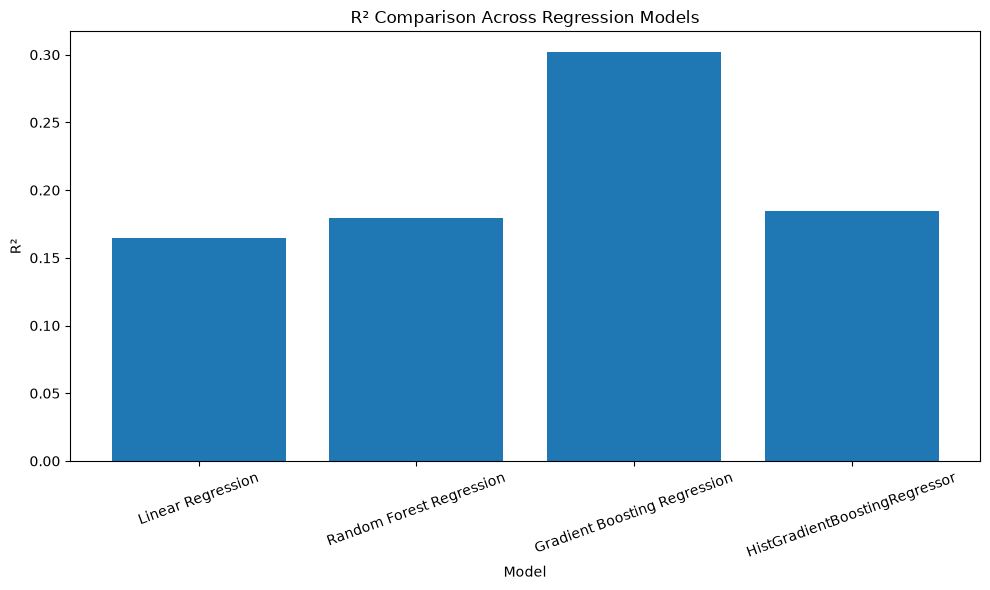

In [653]:
plt.figure(figsize=(10, 6))

plt.bar(results["Model"], results["R²"])

plt.title("R² Comparison Across Regression Models")
plt.xlabel("Model")
plt.ylabel("R²")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

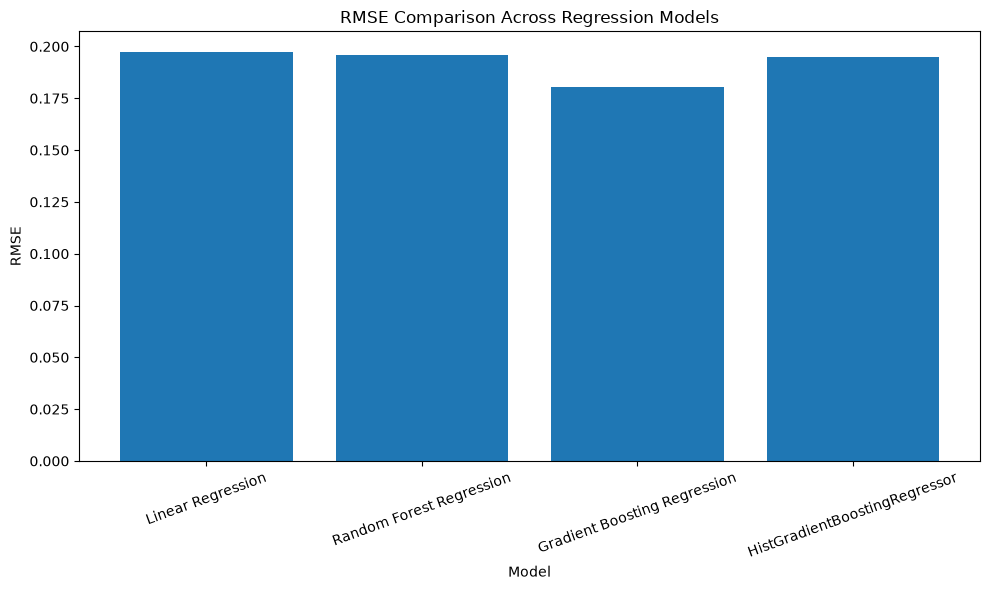

In [654]:
#RMSE comparison
#Lower RMSE values indicate smaller prediction errors.
plt.figure(figsize=(10, 6))

plt.bar(results["Model"], results["RMSE"])

plt.title("RMSE Comparison Across Regression Models")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

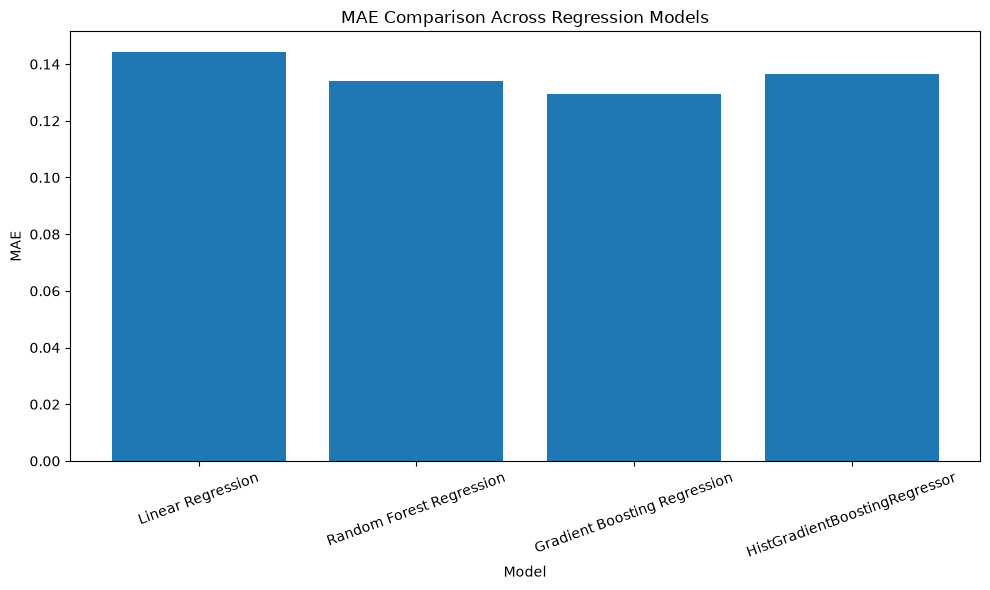

In [655]:
#MAE Comparison
#Lower MAE values indicate that predictions are, on average, closer to the observed customer ratings.
plt.figure(figsize=(10, 6))

plt.bar(results["Model"], results["MAE"])

plt.title("MAE Comparison Across Regression Models")
plt.xlabel("Model")
plt.ylabel("MAE")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

### 8.2 Feature Importance

In [656]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Calculate permutation importance
perm_importance = permutation_importance(
    gradient_boosting_model,
    X_test,
    y_test,
    scoring="r2",
    n_repeats=10,
    random_state=42
)

# Create a DataFrame
feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_importance.importances_mean
})

# Sort from most to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=True
)

print(feature_importance)

           Feature  Importance
0            Price    0.097811
1     Review Count    0.112851
2  Number of Pages    0.139800
3    Genre_Grouped    0.308025


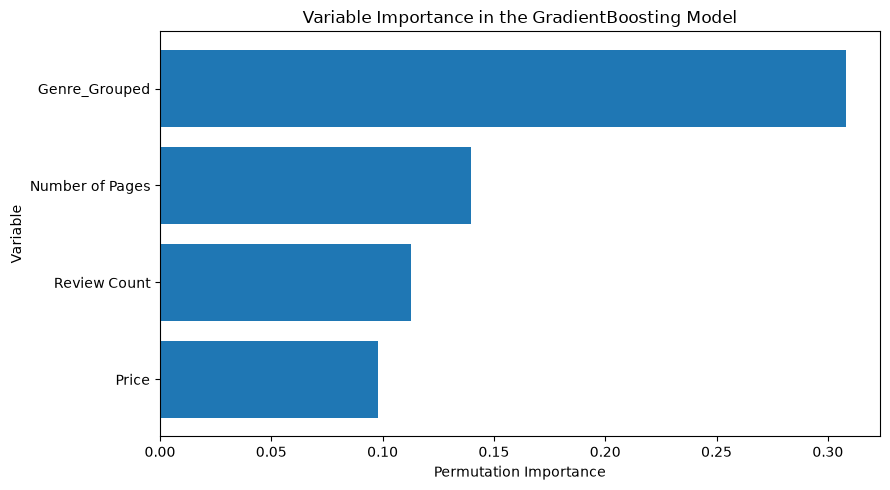

In [657]:
# Variable Importance for GradientBoosting Model

import matplotlib.pyplot as plt

# Sort features from lowest to highest importance
feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Permutation Importance")
plt.ylabel("Variable")
plt.title("Variable Importance in the GradientBoosting Model")

plt.tight_layout()
plt.show()

### SHAP

In [658]:
#%pip install shap

In [659]:
import shap

In [660]:
# Get the fitted preprocessor and final Gradient Boosting model
preprocessor = gradient_boosting_model.named_steps["preprocessor"]
gb_model = gradient_boosting_model.named_steps["model"]

# Transform the test data
X_test_transformed = preprocessor.transform(X_test)

# Convert sparse matrix to dense if necessary
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Convert to DataFrame
X_test_transformed = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)

# Check dimensions
print("Transformed data shape:", X_test_transformed.shape)
print("Number of feature names:", len(feature_names))

# Create SHAP explainer
explainer = shap.TreeExplainer(gb_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test_transformed)

print("SHAP values shape:", shap_values.shape)

Transformed data shape: (967, 220)
Number of feature names: 220
SHAP values shape: (967, 220)


In [661]:

# Get the fitted Gradient Boosting model
gb_model = gradient_boosting_model.named_steps["model"]

# Create SHAP explainer
explainer = shap.TreeExplainer(gb_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test_transformed)

print("SHAP values shape:", shap_values.shape)

SHAP values shape: (967, 220)


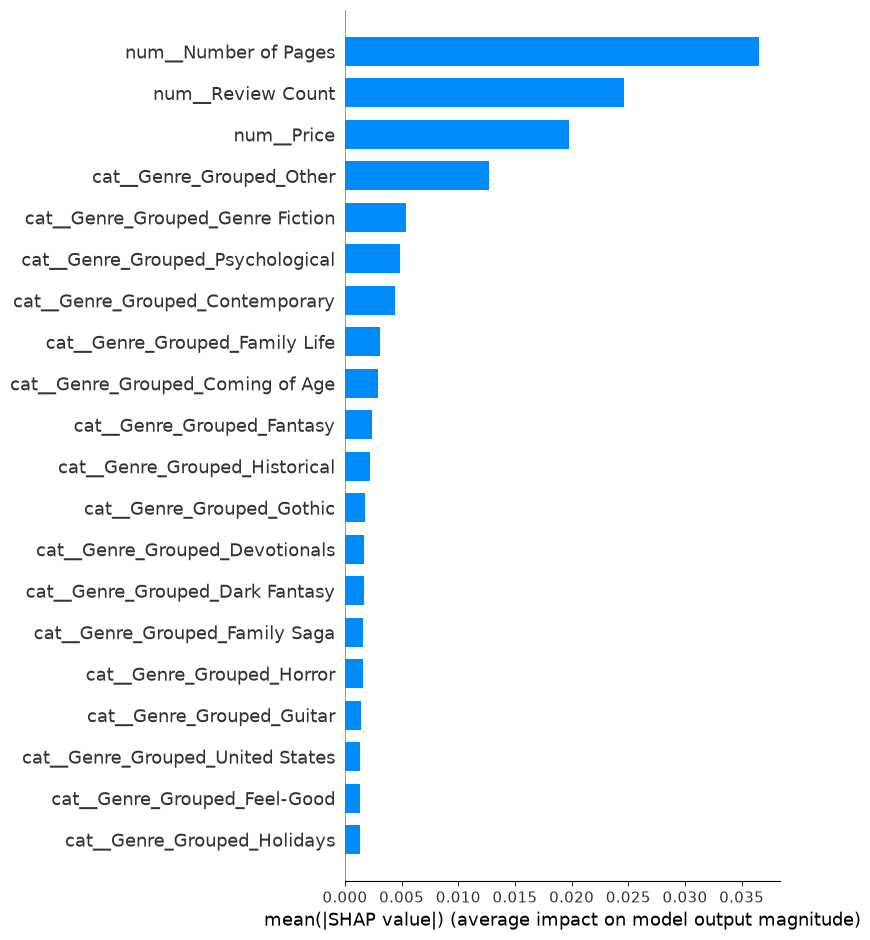

In [662]:
shap.summary_plot(
    shap_values,
    X_test_transformed,
    plot_type="bar"
)

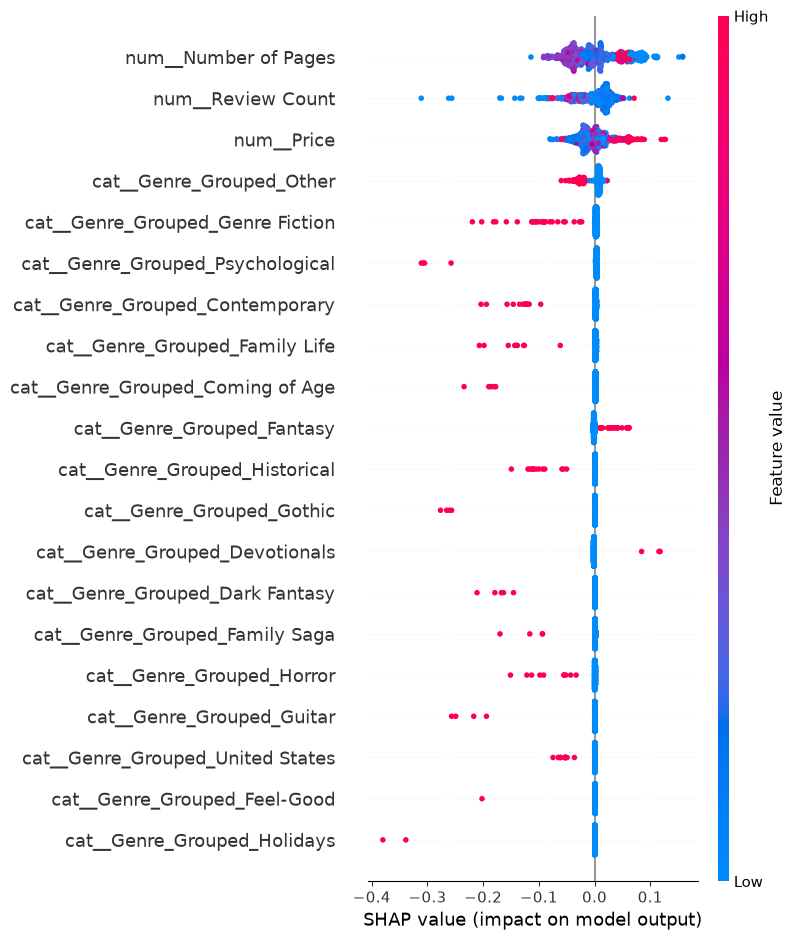

In [663]:
shap.summary_plot(
    shap_values,
    X_test_transformed
)

In [664]:
# Identify the Genre_Grouped columns
genre_columns = [
    col for col in X_test_transformed.columns
    if col.startswith("cat__Genre_Grouped_")
]

# Calculate the combined SHAP contribution of Genre_Grouped
genre_shap = np.abs(
    shap_values[:, [X_test_transformed.columns.get_loc(col) for col in genre_columns]]
).sum(axis=1)

# Calculate mean absolute SHAP for each original feature
original_feature_shap = {
    "Price": np.abs(
        shap_values[:, X_test_transformed.columns.get_loc("num__Price")]
    ).mean(),

    "Review Count": np.abs(
        shap_values[:, X_test_transformed.columns.get_loc("num__Review Count")]
    ).mean(),

    "Number of Pages": np.abs(
        shap_values[:, X_test_transformed.columns.get_loc("num__Number of Pages")]
    ).mean(),

    "Genre_Grouped": genre_shap.mean()
}

shap_importance = (
    pd.DataFrame(
        original_feature_shap.items(),
        columns=["Feature", "Mean Absolute SHAP"]
    )
    .sort_values("Mean Absolute SHAP", ascending=False)
)

shap_importance

,Feature,Mean Absolute SHAP
3,Genre_Grouped,0.080050
2,Number of Pages,0.036555
1,Review Count,0.024610
0,Price,0.019785


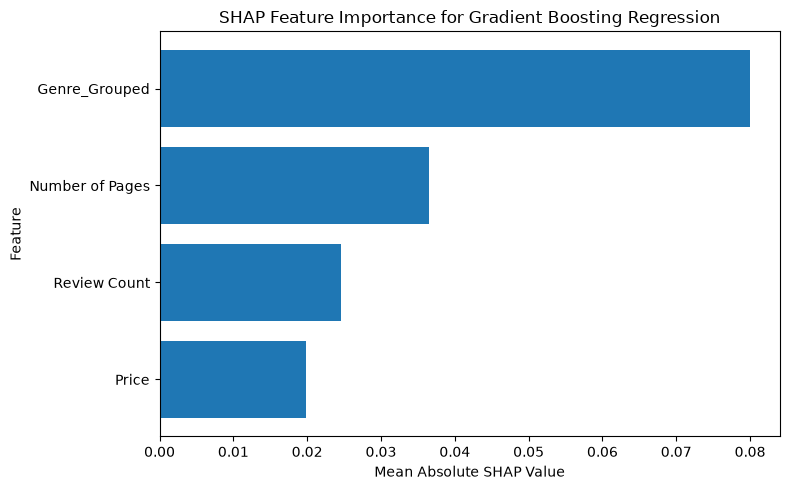

In [680]:
plt.figure(figsize=(8, 5))

plt.barh( shap_importance["Feature"],shap_importance["Mean Absolute SHAP"])

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("SHAP Feature Importance for Gradient Boosting Regression")

# Put the most important feature at the top
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

## 9. Actual vs Predicted Results


### 9.1 Actual vs Predicted

In [696]:
actual_vs_predicted = pd.DataFrame({"Actual": y_test,"Predicted": y_pred_gb})
actual_vs_predicted["Absolute Error"] = (actual_vs_predicted["Actual"] - actual_vs_predicted["Predicted"]).abs()

actual_vs_predicted.head(10)

,Actual,Predicted,Absolute Error
4299,4.4,4.551576,0.151576
1678,4.7,4.659523,0.040477
1042,4.6,4.624103,0.024103
2385,4.5,4.678870,0.178870
1900,4.9,4.677921,0.222079
3211,4.9,4.613517,0.286483
4547,4.4,4.651376,0.251376
2494,4.6,4.636690,0.036690
765,4.9,4.720200,0.179800
1633,4.6,4.543461,0.056539


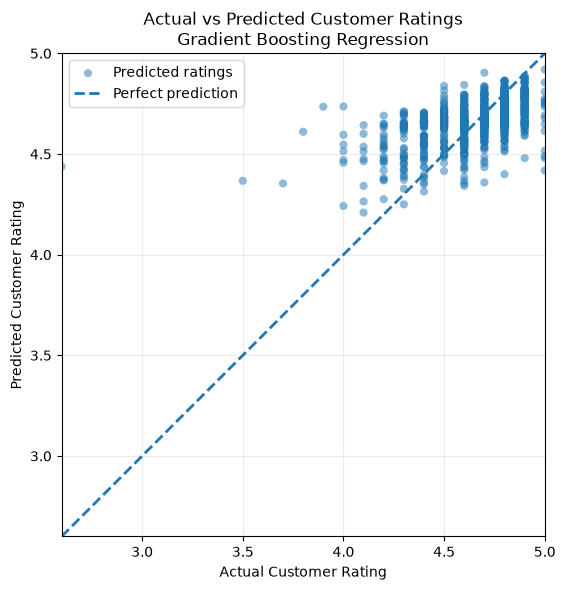

In [697]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_gb, alpha=0.5,s=35,edgecolors="none",label="Predicted ratings")

# Diagonal line showing perfect predictions
min_rating = min(np.min(y_test), np.min(y_pred_gb))
max_rating = max(np.max(y_test), np.max(y_pred_gb))

plt.plot([min_rating, max_rating],[min_rating, max_rating],linestyle="--",linewidth=2,label="Perfect prediction")

plt.xlabel("Actual Customer Rating")
plt.ylabel("Predicted Customer Rating")
plt.title("Actual vs Predicted Customer Ratings\nGradient Boosting Regression")

# Keep both axes on the same scale
plt.xlim(min_rating, max_rating)
plt.ylim(min_rating, max_rating)
plt.gca().set_aspect("equal", adjustable="box")

plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

### 9.2 Residual Analysis

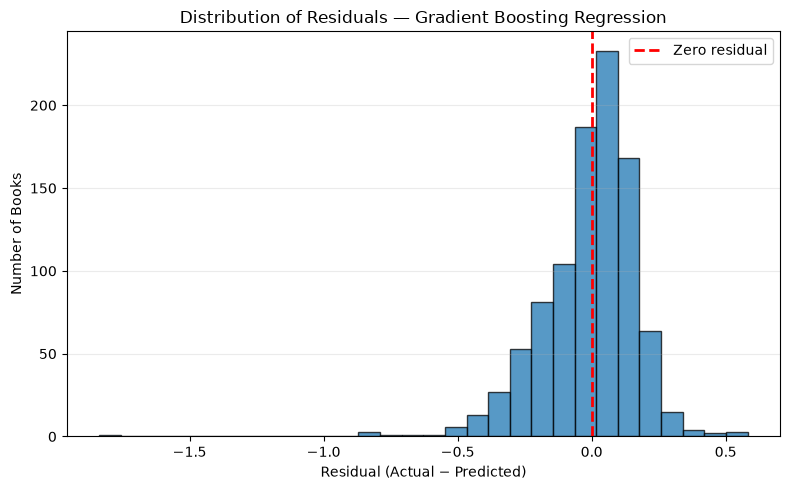

In [700]:
#residual difference 
residuals_gb = y_test - y_pred_gb

plt.figure(figsize=(8, 5))

plt.hist(residuals_gb, bins=30,edgecolor="black", alpha=0.75)
plt.axvline(0,color="red", linestyle="--",linewidth=2,label="Zero residual")

plt.xlabel("Residual (Actual − Predicted)")
plt.ylabel("Number of Books")
plt.title("Distribution of Residuals — Gradient Boosting Regression")
plt.legend()
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

### 9.3 Cross Val

In [694]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    gradient_boosting_model,
    X,
    y,
    cv=5,
    scoring='r2'
)

print("R² scores:", scores)
print("Average R²:", scores.mean())

R² scores: [0.31095557 0.24154886 0.28371914 0.17075691 0.15199375]
Average R²: 0.2317948464262744
